# Artificial Intelligence in Health Care - Exercise 1
## Readmission Risk from Structured Clinical Data

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel dieser Übung ist es das Wiederaufnahmerisiko anhand des Diabetes-Datensatzes zu untersuchen und eine logistische Regression mit einem neuronalen Netz zu vergleichen. Für die Berechechnung des Wiederaufnahemrisikos werden alle bis zu Entlassung verfügbaren Patientendaten miteinbezogen.

### 1 Problem Formulation [1.5P]  

1. **Die klinische Fragestellung:** 
Lässt sich anhand der bis zur Entlassung verfügbaren klinischen Daten vorhersagen, ob ein Patient innerhalb von 30 Tagen erneut stationär aufgenommen wird?


2. **Zielvariable:** Die Zielvariable ist eine erneute stationäre Aufnahme innerhalb von 30 Tagen nach der Entlassung. Die ursprüngliche Variable 'readmitted' besitzt die Ausprägungen <30, >30 und NO. Wir kodieren <30 als 1 und fassen >30 sowie NO zur Klasse 0 zusammen`. Da der Fokus auf frühen Wiederaufnahmen liegt macht diese Binarisierung am meisten Sinn, da Fälle ohne einer oder mit einer späten Wiederaufnahmen für unserenm Fall nicht passen. Die 30-Tage-Grenze ist in der Praxis üblich: In den USA werden Krankenhäuser im Rahmen des Hospital Readmissions Reduction Program für hohe 30-Tage-Wiederaufnahmeraten finanziell bestraft, und auch das Paper verwendet diese Definition. Frühe Wiederaufnahmen hängen eher mit dem vorherigen Aufenthalt zusammen (z. B. zu frühe Entlassung, fehlende Nachbetreuung) und sind daher durch das Entlassungsmanagement beeinflussbar. Nachteil: Die Klasse 0 enthält auch Patient:innen, die später als 30 Tage wieder aufgenommen wurden.

3. **Untersuchte Population:** Zur Ermittlung der ein- bzw ausgeschlossenen Fälle wurde die Entlassungsart (discharge_disposition_id) herangezogen. Die zugehörigen Kategorien und ihre Beschreibungen sind in IDS_mapping.csv dokumentiert. Folgende Aufenthalte wurden ausgeschlossen:

    * Personen die verstorben sind (discharge_disposition_id = 11, 19, 20, 21): Eine Wiederaufnahme ist nicht möglich.  
    * Personen die keinen eindeutig abgeschlossenen Aufenthalt haben (discharge_disposition_id = 9, 12): Es ist nicht klar ob eine Entlassung stattgefunden hat. Damit fehlt ein klarer Ausgangspunkt für die Betrachtung einer Wiederaufnahme innerhalb von 30 Tagen.
    *  Personen die in ein Hospiz oder ähnliches entlassen wurden (discharge_disposition_id = 13, 14): einerseits ist die Wahrscheinlichkeit ist höher dass diese Personen zeitnahe versterben andererseits bekommen diese eine intensivere Betreuung.
    * Personen deren Enlassungsart unklar oder nicht dokumentiert ist (discharge_disposition_id = 18, 25, 26): Bei diesen Aufenthalten lässt sich nicht zuverlässig beurteilen, ob die festgelegten Einschlusskriterien erfüllt sind.

Die Grundpopulation ist durch den Datensatz bereits eingeschränkt: stationäre Aufenthalte von Diabetiker:innen mit einer Dauer von 1–14 Tagen, bei denen Labortests durchgeführt und Medikamente verabreicht wurden. Anders als im Paper (dort wurde nur der erste Aufenthalt pro Patient:in verwendet) behalten wir alle Aufenthalte und berücksichtigen die Mehrfachaufenthalte durch einen patientenweise gruppierten Split (siehe 2b).

4. Zielgruppe (Anwender) sowie eine konkrete Entscheidung, die mithilfe der Vorhersage unterstützt werden soll.    
**Anwender:** Pflegepersonen im Entlassungsmanagement  
**Unterstützte Entscheidung:** Ist für einen Patienten eine intensivere Nachbetreuung notwendig?  
**Begründung:** Das entwickelte Modell soll Pflegepersonen im Rahmen des Entlassungsmanagements unterstützen, Patient:innen mit einem erhöhten Risiko für eine Wiederaufnahme innerhalb von 30 Tagen zu identifizieren. Auf dieser Grundlage können sie bereits vor der Entlassung prüfen, ob zusätzliche Maßnahmen sinnvoll sind, beispielsweise frühere oder häufigere Nachkontrolltermine. Die Vorhersage dient dabei als Ergänzung zur pflegerischen und ärztlichen Einschätzung.

### 2 Data Exploration [2.5P]
Zunächst verschaffen wir uns einen Überblick über die vorhandenen Daten. Dazu untersuchen wir die Datenstruktur, insbesondere die Anzahl der Krankenhausaufenthalte und Spalten sowie die Datentypen der Merkmale. Anschließend betrachten wir die Verteilungen numerischer und kategorialer Merkmale und prüfen auffällige Werte sowie mögliche Ausreißer. Abschließend bestimmen wir die absoluten und relativen Häufigkeiten der Wiederaufnahmekategorien (<30, >30, NO) sowie der daraus abgeleiteten binären Zielvariable.

#### 2a Struktur, Verteilung und Klassenverteilung

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import torch
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

keras 3.15.1 | backend torch


In [2]:
# Datenstruktur untersuchen
# Datensatz importieren
diabetes_orig = pd.read_csv("diabetic_data.csv", na_values=["?"]) # ? bedeutet fehlende Werte

# Größe des Datensatzes
print(f"Der Datensatz hat {diabetes_orig.shape[0]} Zeilen und {diabetes_orig.shape[1]} Spalten.")        #101766 Einträge und 50 Spalten

# erste Zeile anzeigen  |  Identifizieren der nummerischen und kategorischen Variablen und der Outcome-Variable
display(diabetes_orig.head())

# diabetes.info()  #zeigt Spaltennamen, Datentypen und die Anzahl nicht fehlender Einträge
diabetes_orig.isna().sum()   #Überblick über fehlende werte

Der Datensatz hat 101766 Zeilen und 50 Spalten.


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

**Datenstruktur:** Der Datensatz hat 101766 Einträge und 50 Spalten. Jeder Eintrag entspricht einem stationären Krankenhausaufenthalt. Ein Patient kann aufgrund mehrerer Aufenthalte mehrfach im Datensatz vorkommen.  
Anhand der Datensatzbeschreibung (https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) wurden die Variablen als nummerische oder kategorisch eingeordnet:  
**kategorisch:** race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id, payer_code, medical_specialty, diag_1, diag_2, diag_3, change, diabetesMed, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone  
**nummerisch:** time_in_hospital, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, number_diagnoses

readmitted
NO     49790
>30    34097
<30    10752
Name: count, dtype: int64

Aufenthalte vorher: 101766
Aufenthalte danach: 94639
Ausgeschlossen: 7127


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,94639.000000,94639.000000,94639.000000,94639.000000,94639.000000,94639.000000,94639.000000,94639.000000
mean,4.346570,42.942497,1.325151,15.986908,0.381629,0.205856,0.632836,7.432824
std,2.949568,19.746593,1.696281,8.045838,1.287953,0.957438,1.264815,1.931017
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
count,92439,94639,94639,3093,94639,94639,94639,59904,49021,94621,...,94639,94639,94639,94639,94639,94639,94639,94639,94639,94639
unique,5,3,10,9,8,17,17,17,72,712,...,1,1,4,4,2,2,2,2,2,2
top,Caucasian,Female,[70-80),[75-100),1,1,7,MC,InternalMedicine,428,...,No,No,No,No,No,No,No,No,No,Yes
freq,70906,50947,24001,1297,50206,60234,53548,31316,14017,6289,...,94639,94639,43010,93941,94626,94638,94637,94638,50045,73650


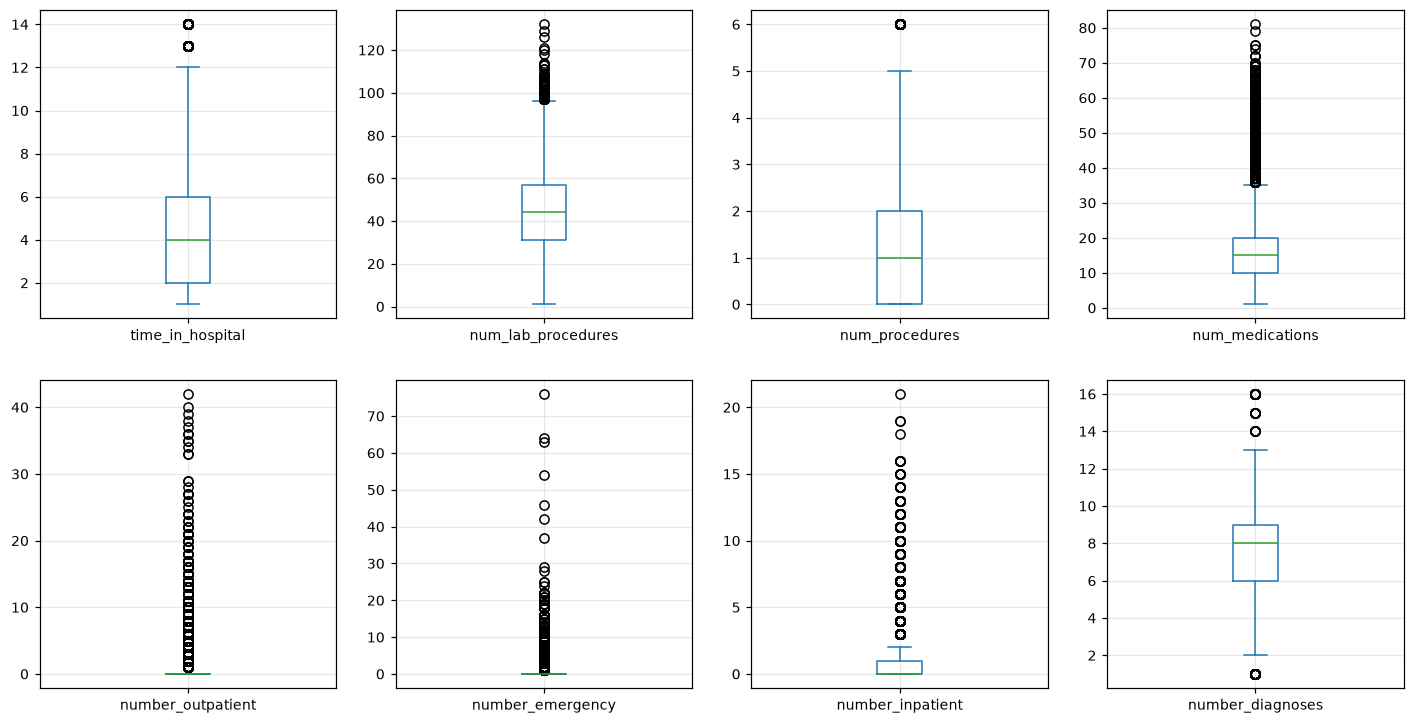

In [3]:
#Datensatz bereinigen (Ausschlusskriterien)
ausschluss_id = [    # alle ids der Ausschlusskriterien sammeln
    11, 19, 20, 21,  # Verstorben
    9, 12,           # Kein eindeutig abgeschlossener Aufenthalt
    13, 14,          # Hospiz
    18, 25, 26       # Entlassungsart unklar
]

#in den finalen Datensatz nur jene Einträge aufnehmen die nicht in den Ausschlusskriterien vorkommen und die discharge_disposition_id nicht leer ist
diabetes = diabetes_orig.loc[
    ~diabetes_orig["discharge_disposition_id"].isin(ausschluss_id) # ~ -> Negation, d.h. alle Einträge mit diesen IDs werden ausgeschlossen
    & diabetes_orig["discharge_disposition_id"].notna()         
]

#Kontrolle der Klassenverteilung der Outcomevariable
display(diabetes["readmitted"].value_counts())  #normalize=True -> relative Häufigkeiten anzeigen

#Anzahl der Einträge vor und nach der Bereinigung
print("Aufenthalte vorher:", len(diabetes_orig))
print("Aufenthalte danach:", len(diabetes))
print("Ausgeschlossen:", len(diabetes_orig) - len(diabetes))

#Datensatz in nummerische und kategorische Variablen einordnen
numeric_var = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

#kategorisch sind nur jene Variablen die im diabetes Datensatz sind und nicht in den nummerischen vorkommen oder eines dieser Variablen sind [...]
categoric_var = [
    column for column in diabetes.columns
    if column not in numeric_var
    + ["encounter_id", "patient_nbr", "readmitted"]     #readmitted ist Outcome Variable
]

#Verteilung der nummerischen und kategorischen Variablen (in der untersuchten Population)
display(diabetes[numeric_var].describe())

#Verteilung der nummerischen Variablen als Boxplot darstellen
diabetes[numeric_var].plot(
    kind="box",
    subplots=True,
    layout=(2, 4),
    figsize=(16, 8),
    sharey=False
)

display(diabetes[categoric_var].astype("category").describe())

**Interpretation der Verteilung:**  
Die Verteilungen der numerischen Variablen wurden anhand von Boxplots untersucht. Dabei zeigen mehrere Merkmale potenzielle Ausreißer. Insbesondere bei number_outpatient und num_medications fallen hohe Werte auf.
Laut Datensatzbeschreibung erfasst number_outpatient die Anzahl ambulanter Besuche im gesamten Jahr vor dem jeweiligen Krankenhausaufenthalt. Hohe Werte können daher beispielsweise bei Patienten mit regelmäßigem Behandlungsbedarf grundsätzlich plausibel sein. num_medications beschreibt die Anzahl unterschiedlicher generischer Medikamentenbezeichnungen, die während des gesamten Aufenthalts verabreicht wurden. Die Variable gibt somit weder die Anzahl einzelner Tabletten noch die Anzahl gleichzeitig eingenommener Medikamente an. 
Die auffälligen Werte werden zunächst beibehalten, da ihre Höhe allein keinen Datenfehler belegt und sie als plusibel eingestuft werden. Ihre tatsächliche Richtigkeit lässt sich anhand der verfügbaren Angaben jedoch nicht abschließend bestätigen.
Bei den kategorialen Merkmalen ist die Altersgruppe 70–80 Jahre am häufigsten vertreten. Die Medikamentenvariablen examide und citoglipton enthalten im untersuchten Datensatz ausschließlich die Kategorie „No“ und liefern somit keine Information zur Unterscheidung der Aufenthalte.


In [4]:

#Outcomevariable in binäre Variable mappen
target_var = diabetes["readmitted"].map({"NO": 0, 
                                         ">30": 0, 
                                         "<30": 1}) 
#target_var hinzufügen
diabetes["readmitted"] = target_var

#Variable change in binäre Variable mappen
diabetes["change"] = diabetes["change"].map({"Ch": 1, "No": 0})
#Variable diabetesMed in binäre Variable mappen
diabetes["diabetesMed"] = diabetes["diabetesMed"].map({"Yes": 1, "No": 0})

#drop examide und citoglipton da diese Variablen nur No beinhelten
diabetes = diabetes.drop(columns=["examide", "citoglipton"])


#Ausgabe der Klassenverteilung in einem DataFrame
class_distr = pd.DataFrame({"Anzahl": target_var.value_counts(),
                            "Anteil (%)": target_var.value_counts(normalize=True) * 100})

display(class_distr.round(2))  #Ausgabe und auf 2 Nachkommastellen runden

,Anzahl,Anteil (%)
readmitted,,
0,83887,88.64
1,10752,11.36


Nach Anwendung der Ausschlusskriterien verbleiben 94.639 von ursprünglich 101.766 Aufenthalten. Davon weisen 10.752 Aufenthalte (11,36 %) eine frühe Wiederaufnahme (<30 Tagen) auf. Die übrigen 83.887 Aufenthalte (88,64 %) gehören zur negativen Klasse (>30 Tage oder keine Wiederaufnahme). Es besteht somit ein deutliches Klassenungleichgewicht. Für den späteren Modellvergleich reicht die Accuracy allein daher nicht aus: Ein Modell, das ausschließlich die negative Klasse vorhersagt, würde bereits eine Accuracy von 88,64 % erreichen, ohne eine einzige frühe Wiederaufnahme zu erkennen. Deshalb werden zusätzlich die AUROC, die Sensitivität – der Anteil tatsächlich früher Wiederaufnahmen, die korrekt erkannt werden – sowie die Konfusionsmatrix betrachtet.

#### 2b Aufenthalte vs Patienten
Da wie bereits zuvor erwähnt ein Patient öfters im Datensatz vorkommen kann aufgrund von mehreren Aufenthalten wird im nächsten Schritt die Anzahl der Krankenhausaufenthlte die zum selben Pateinten gehören ermittelt.

In [5]:
#Anzahl der Aufenthalte pro Patient
display(diabetes.groupby("patient_nbr").size().reset_index(name="Anzahl Aufenthalte")) #.sort_values(by="Anzahl Aufenthalte", ascending=False)   .discribe()

print("Anzahl Aufenthalte:", len(diabetes))
print("Anzahl der Patienten:", diabetes["patient_nbr"].nunique())

#wie viele Patienten jeweils wie viele Aufenthalte haben:
display(diabetes.groupby("patient_nbr").size().value_counts())

,patient_nbr,Anzahl Aufenthalte
0,135,2
1,378,1
2,729,1
3,774,1
4,927,1
...,...,...
67303,189351095,1
67304,189365864,1
67305,189445127,1
67306,189481478,1


Anzahl Aufenthalte: 94639
Anzahl der Patienten: 67308


1     51949
2      9669
3      3042
4      1250
5       630
6       309
7       173
8       101
9        60
10       37
11       21
12       17
13       13
15        7
20        6
18        5
17        4
14        3
16        3
21        2
23        2
19        2
28        1
22        1
40        1
Name: count, dtype: int64

Die 94.639 Aufenthalte stammen von 67.308 Patient:innen. 51.949 Patient:innen (77,2 %) haben genau einen Aufenthalt, 15.359 (22,8 %) haben mehrere, maximal 40. Diese Patient:innen mit mehreren Aufenthalten stellen zusammen 42.690 Aufenthalte, also ca. 45 % des Datensatzes. Da einzelne Patienten mehrere Krankenhausaufenthalte aufweisen, erfolgt die Aufteilung in Trainings-, Validierungs- und Testdaten gruppiert nach der patient_nbr, sodass alle Aufenthalte eines Patienten ausschließlich einem Teilset zugeordnet werden. Ohne patientenweise Aufteilung könnten Aufenthalte derselben Person in mehreren Teilsets vorkommen, wodurch die Vorhersage aufgrund wiederkehrender ähnlicher Merkmale positiver ausfallen könnte.

#### 2c Missing Values
Im nächsten Schritt schauen wir uns die fehlenden Werte an. Neben weight, medical_specialty und payer_code betrachten wir auch max_glu_serum, A1Cresult und race, da diese ebenfalls fehlende Werte haben. Für jede Variable geben wir Anzahl und Anteil aus und überlegen, warum die Werte fehlen könnten.

In [6]:
#Anzahl und prozentuellen anteil missingValues der Spalte weight, medical_specialty, payer_code ausgeben
missing_values = pd.DataFrame({"Anzahl missing Values": diabetes[["weight", "medical_specialty", "payer_code", "max_glu_serum", "A1Cresult", "race"]].isna().sum()})
missing_values["Prozentueller Anteil"] = (missing_values["Anzahl missing Values"] / len(diabetes) * 100).round(2)
display(missing_values)


,Anzahl missing Values,Prozentueller Anteil
weight,91546,96.73
medical_specialty,45618,48.20
payer_code,34735,36.70
max_glu_serum,89842,94.93
A1Cresult,78632,83.09
race,2200,2.32


Betrachtet man den Anteil der fehlenden Werte, ergeben sich für die einzelnen Variablen folgende Entscheidungen:

- **weight (96,7 % fehlend):** Laut Paper mussten Krankenhäuser das Gewicht vor 2009 nicht verpflichtend strukturiert erfassen. Da fast alle Werte fehlen und eine Ergänzung wenig sinnvoll wäre, entfernen wir die Variable aus dem Datensatz.

- **medical_specialty (48,2 % fehlend):** Diese Variable beschreibt die Fachrichtung des aufnehmenden Arztes und kann wichtige Informationen liefern. Deshalb behalten wir sie bei und fügen die Kategorie `IS_MISSING` für fehlende Werte hinzu. So bleiben alle Patient:innen im Datensatz erhalten.

- **payer_code (36,7 % fehlend):** Da der Versicherungsträger für meine Fragestellung wenig relevant ist, entfernen wir diese Variable aus dem Datensatz. (selina hat ihn drin)

- **max_glu_serum (94,9 % fehlend) und A1Cresult (83,1 % fehlend):** Die fehlenden Werte bedeuten, dass die jeweiligen Tests nicht durchgeführt wurden. Da dies vom Zustand der Patient:innen abhängen kann, behalten wir `None` als eigene Kategorie bei, anstatt Werte zu schätzen.

- **race (ca. 2 % fehlend):** Wir fügen die Kategorie `IS_MISSING` hinzu, anstatt fehlende Werte durch die häufigste Kategorie zu ersetzen.

- **diag_1 bis diag_3:** Fehlende Diagnosecodes werden bei der Gruppierung nach ICD-9 als eigene Gruppe „Fehlender Code“ berücksichtigt.

Mit diesen Anpassungen entscheiden wir für jede Variable einzeln, wie wir mit den fehlenden Werten umgehen. Dabei möchten wir wichtige Informationen erhalten und vermeiden, fehlende Werte durch ungenaue Schätzungen zu ersetzen.

In [7]:
#drop Colum weight
diabetes = diabetes.drop(columns=["weight"])

#drop Colum payer_code
diabetes = diabetes.drop(columns=["payer_code"])

#fehlende Fachrichtung "IS_MISSING" eintragen
diabetes["medical_specialty"] = diabetes["medical_specialty"].fillna("IS_MISSING")

#fehlende Ethnie ebenfalls als eigene Kategorie (statt mit der häufigsten Kategorie zu imputieren)
diabetes["race"] = diabetes["race"].fillna("IS_MISSING")

#"None" bei den Laborwerten bedeutet: Test wurde nicht durchgeführt -> eigene Kategorie, NICHT imputieren
diabetes["max_glu_serum"] = diabetes["max_glu_serum"].fillna("nicht gemessen")
diabetes["A1Cresult"] = diabetes["A1Cresult"].fillna("nicht gemessen")

display(diabetes)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,...,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,IS_MISSING,...,No,Up,No,No,No,No,No,1,1,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,IS_MISSING,...,No,No,No,No,No,No,No,0,1,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,IS_MISSING,...,No,Up,No,No,No,No,No,1,1,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,IS_MISSING,...,No,Steady,No,No,No,No,No,1,1,0
5,35754,82637451,Caucasian,Male,[50-60),2,1,2,3,IS_MISSING,...,No,Steady,No,No,No,No,No,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,443847548,100162476,AfricanAmerican,Male,[70-80),1,3,7,3,IS_MISSING,...,No,Down,No,No,No,No,No,1,1,0
101762,443847782,74694222,AfricanAmerican,Female,[80-90),1,4,5,5,IS_MISSING,...,No,Steady,No,No,No,No,No,0,1,0
101763,443854148,41088789,Caucasian,Male,[70-80),1,1,7,1,IS_MISSING,...,No,Down,No,No,No,No,No,1,1,0
101764,443857166,31693671,Caucasian,Female,[80-90),2,3,7,10,Surgery-General,...,No,Up,No,No,No,No,No,1,1,0


#### 2d Zielpopulation ermitteln
Der 4. Punkt der 2. Aufgabe wurde bereits umgesetzt indem die Entlassungsarten mithilfe des IDS_mapping.csv analysiert wurden. Insgesamt wurden hier 7127 Aufenthalte entfernt; die untersuchte Population umfasst damit 94.639 Aufenthalte. Eine genauere Erläuterung diesbezüglich ist in Aufgabe 1 'Problem Formulation' nachzulesen.

#### 2e ICD-9 Code Gruppierung
Die ICD-9-Codes weisen eine hohe Anzahl unterschiedlicher Kategorien auf. Deshalb werden sie anhand eines einheitlichen, klinisch begründeten Schemas zu übergeordneten Diagnosegruppen zusammengefasst. Dies reduziert die Anzahl seltener Kategorien und ermöglicht eine übersichtlichere Verarbeitung der Diagnoseinformationen.

In [8]:
#Häufigkeit von diagnoses in den Spalten diag_1, diag_2, diag_3
diagnoses = pd.concat([diabetes["diag_1"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten hauptdiagnosen
diagnoses = pd.concat([diabetes["diag_2"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten Nebendiagnosen
diagnoses = pd.concat([diabetes["diag_3"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten weiteren hauptdiagnosen


diagnoses_cols = ["diag_1", "diag_2", "diag_3"]

display(pd.DataFrame({
    "Unterschiedliche ICD-9-Codes": diabetes[diagnoses_cols].nunique(),
    "Fehlende Codes": diabetes[diagnoses_cols].isna().sum()
}))

diag_1
428      6289
414      6051
786      3751
486      3256
410      3176
427      2605
491      2167
715      2042
682      1941
780      1899
996      1844
434      1838
276      1758
250.8    1605
599      1527
38       1463
584      1415
250.6    1138
V57      1077
820      1024
Name: count, dtype: int64

diag_2
276       6383
428       6080
250       5713
427       4657
401       3515
599       3099
496       3058
403       2643
414       2453
411       2376
250.02    1989
707       1862
585       1744
584       1512
285       1462
491       1460
250.01    1387
780       1367
682       1358
425       1316
Name: count, dtype: int64

diag_3
250       10832
401        7753
276        4822
428        4205
427        3621
414        3414
496        2366
403        2201
272        1881
585        1848
599        1791
250.02     1291
V45        1289
707        1245
780        1238
285        1144
425        1057
250.6      1016
424        1004
305         876
Name: count, dtype: int64

,Unterschiedliche ICD-9-Codes,Fehlende Codes
diag_1,712,18
diag_2,742,343
diag_3,782,1339


Im ersten Schritt wurde ein Überblick über die Diagnosedaten erstellt. Dazu wurden für jede der drei Diagnosespalten die 20 häufigsten Codes sowie die Anzahl unterschiedlicher und fehlender Diagnosecodes ermittelt.
Aufgrund der hohen Anzahl unterschiedlicher Codes wurde ein bereits vorhandenes Gruppierungsschma gewählt. Als Grundlage dient die Einteilung aus Table 2 der Originalpublikation. Die Autoren fassen dort die Hauptdiagnosen zu übergeordneten Krankheitsgruppen zusammen. Wir übernehmen die Gruppen direkt aus dem Paper. Alle Codes, die keiner dieser Gruppen zugeordnet werden können (auch die E- und V-Codes), fassen wir wie im Paper unter „Sonstige“ zusammen.

Für die Zuteilung der ICD-9-Codes wird eine Funktion definiert und auf allen drei Spalten angewendet.

In [9]:
#Funktion zur Kategorisierung der Diagnosen
def get_diag_group(diag_code):
    #überprüfen ob code leer ist
    if pd.isna(diag_code):
        return "Fehlender Code"

    #wenn nciht dann code als string und leerzeichen entfernen (und in Großbuchstaben umwandeln) für Einheitliche abfragen
    diag_code = str(diag_code).strip().upper()

    #Codes mit E und V der Gruppe Sonstiges zuteilen
    if diag_code.startswith("V") or diag_code.startswith("E"):
        return "Sonstige"

    #Hauptcode bestimmen (nur 250 statt 250.13) -> ist selbe Kategorie
    try :
        icd9_code = int(diag_code.split(".")[0])  #nur der Hauptcode (vor dem Punkt)
    except ValueError:
        return "Fehlerhafter Code"

    #Zuteilung zu Gruppe abhängig vom "Hauptcode"
    if 390 <= icd9_code <= 459 or icd9_code == 785:
        return "Kreislauferkrankungen"
    elif 460 <= icd9_code <= 519 or icd9_code == 786:
        return "Atmungserkrankungen"
    elif 520 <= icd9_code <= 579 or icd9_code == 787:
        return "Verdauungserkrankungen"
    elif icd9_code ==250:
        return "Diabetes"
    elif 800 <= icd9_code <= 999:
        return "Verletzungen"
    elif 710 <= icd9_code <= 739:
        return "Muskuloskeletterkrankungen"
    elif 580 <= icd9_code <= 629 or icd9_code == 788:
        return "Genitourinäre Erkrankungen"
    elif 140 <= icd9_code <= 239:
        return "Neoplasmen" 
    else:
        return "Sonstige"


#Ergebnis in neuen Spalten speichern
for col in diagnoses_cols:
    diabetes[f"{col}_group"] = diabetes[col].apply(get_diag_group)      #diag_code ist Inhalt der aktuellen Zeile von col #.apply übergibt jeden Wert dieser Spalte einzeln an die Funktion.


#Kontrolle der Kategorisierung der Diagnosen anzeigen (Anzeigen der beiden zusammengehörigen relevanten Spalten mit ersten 10 Datensätzen)
display(diabetes[
    ["diag_1", "diag_1_group",
     "diag_2", "diag_2_group",
     "diag_3", "diag_3_group"]
].head(10))

#Anzahl der jeweiligen Diagnosen in der jeweiligen Gruppe (auswahl der Spalte)
for col in ["diag_1_group", "diag_2_group", "diag_3_group"]:
    display(diabetes[col].value_counts())

,diag_1,diag_1_group,diag_2,diag_2_group,diag_3,diag_3_group
1,276,Sonstige,250.01,Diabetes,255,Sonstige
2,648,Sonstige,250,Diabetes,V27,Sonstige
3,8,Sonstige,250.43,Diabetes,403,Kreislauferkrankungen
4,197,Neoplasmen,157,Neoplasmen,250,Diabetes
5,414,Kreislauferkrankungen,411,Kreislauferkrankungen,250,Diabetes
6,414,Kreislauferkrankungen,411,Kreislauferkrankungen,V45,Sonstige
7,428,Kreislauferkrankungen,492,Atmungserkrankungen,250,Diabetes
8,398,Kreislauferkrankungen,427,Kreislauferkrankungen,38,Sonstige
9,434,Kreislauferkrankungen,198,Neoplasmen,486,Atmungserkrankungen
10,250.7,Diabetes,403,Kreislauferkrankungen,996,Verletzungen


diag_1_group
Kreislauferkrankungen         27927
Sonstige                      17065
Atmungserkrankungen           13324
Verdauungserkrankungen         8967
Diabetes                       8265
Verletzungen                   6558
Genitourinäre Erkrankungen     4837
Muskuloskeletterkrankungen     4695
Neoplasmen                     2983
Fehlender Code                   18
Name: count, dtype: int64

diag_2_group
Kreislauferkrankungen         29466
Sonstige                      25037
Diabetes                      11926
Atmungserkrankungen            9919
Genitourinäre Erkrankungen     7852
Verdauungserkrankungen         3904
Verletzungen                   2274
Neoplasmen                     2237
Muskuloskeletterkrankungen     1681
Fehlender Code                  343
Name: count, dtype: int64

diag_3_group
Kreislauferkrankungen         28116
Sonstige                      27432
Diabetes                      15988
Atmungserkrankungen            6691
Genitourinäre Erkrankungen     6171
Verdauungserkrankungen         3679
Muskuloskeletterkrankungen     1815
Verletzungen                   1814
Neoplasmen                     1594
Fehlender Code                 1339
Name: count, dtype: int64

Durch die Gruppierung der einzelnen ICD-9-Codes konnte die Anzahl der unterschiedlichen Diagnosen, die je nach Diagnosefeld zwischen 712 und 782 lag, auf neun übergeordnete Krankheitsgruppen reduziert werden. Dabei wurden Hauptdiagnosen, Nebendiagnosen und weitere Nebendiagnosen jeweils separat gruppiert und in neuen Spalten gespeichert.

Der Vergleich der drei resultierenden Diagnosegruppen zeigt, dass Herzerkrankungen sowohl bei den Hauptdiagnosen als auch bei den Nebendiagnosen am häufigsten vorkommen, gefolgt von der Gruppe „Sonstige Diagnosen“. Bei den Nebendiagnosen und den weiteren Nebendiagnosen steht Diabetes jeweils an dritter Stelle.

Auffällig ist außerdem, dass lediglich 18 Fälle keine dokumentierte Hauptdiagnose aufweisen. Die Anzahl der fehlenden Diagnosecodes nimmt hingegen von den Hauptdiagnosen über die Nebendiagnosen bis zu den weiteren Nebendiagnosen zu. Dies könnte darauf hindeuten, dass insbesondere zusätzliche Diagnosen nicht immer vollständig dokumentiert wurden, beispielsweise aufgrund von Unterschieden in der Dokumentationspraxis oder im klinischen Alltag. Die tatsächlichen Ursachen für die fehlenden Angaben lassen sich aus den vorliegenden Daten jedoch nicht eindeutig ableiten.

### Preprocessing 
Bevor die logistische Regression und das neuronale Netz trainiert werden, erfolgt die Vorverarbeitung der Daten. Dabei orientieren wir uns an den Schritten des bereitgestellten Notebooks NB2.  
Der Datensatz wird patientenweise in 60 % Trainingsdaten, 25 % Testdaten und 15 % Validierungsdaten aufgeteilt.
Die beiden Variablen examide und citoglipton werden nicht in die Features aufgenommen, da sie nur die Antwort No enthalten und somit keine zusätzliche Information liefern.

In [ ]:
#Features definieren (alle Spalten außer Outcomevariable und IDs und den ursprünglichen Diagnosenspalten) sortiert nach der Patient_id
X_df = diabetes.drop(columns=[
    "readmitted",   # Zielvariable
    "encounter_id", # Aufenthalts-ID
    "patient_nbr",  # Patienten-ID
    "diag_1",       # ursprünglichen Diagnosecodes irrelevant, da wir die Gruppierung verwenden
    "diag_2",
    "diag_3"
]).copy()

# Zielvariable definieren (1 = <30 Tage, 0 = >30 Tage oder keine Wiederaufnahme) sortiert nach der Patient_id
y = (diabetes["readmitted"] == 1).astype(int).values

#Einteilung der Patiente in Gruppen, damit die Aufteilung in Trainings-, Validierungs- und Testset patientenbasiert erfolgt (d.h. alle Aufenthalte eines Patienten sind in einem Set)
groups = diabetes["patient_nbr"]

from sklearn.model_selection import GroupShuffleSplit
SEED = 42  # Zufallszahl für Reproduzierbarkeit

#zufällige Aufteilung der Patienten in Trainings-, Validierungs- und Testset (60% / 25% / 15%)
split = GroupShuffleSplit(n_splits=1, train_size=0.6, random_state=SEED)
train_idx, tmp_idx = next(split.split(X_df, y, groups=groups))      #groups sorgt dafür, dass alle Aufenthalte eines Patienten in einem Set sind
                                                                    #Ausgabe = ZEILENPOSITIONEN, keine Patienten-IDs

#Trainigsdatensatz in X_train und y_train aufteilen -> ilco wählt Zeilenpositionen aus
#gleiche Position für x und y
X_train_df = X_df.iloc[train_idx]
Y_train = y[train_idx]


#temporärer Datensatz für Validierung und Testset speichern
X_tmp = X_df.iloc[tmp_idx]
Y_tmp = y[tmp_idx]
#Gruppen für temporären Datensatz speichern
groups_tmp = groups.iloc[tmp_idx]  

# 2. Die restlichen 40 % in Validierung und Test aufteilen. Der erste zurückgegebene Teil ist das Validierungsset:
#    15 % / 40 % = 0,375 -> train_size=0.375 (Validierung), der Rest 0,625 ist das Testset (25 %)
split = GroupShuffleSplit(n_splits=1, train_size=0.375, random_state=SEED)  #0.375 * 0.4 = 0.15
val_idx, test_idx = next(split.split(X_tmp, Y_tmp, groups=groups_tmp))     #neue Positionen für Validierungs- und Testset
#Wir verwenden 25 % der Daten als Testset, weil ein größeres Testset eine stabilere und verlässlichere Schätzung der finalen Modellleistung ermöglicht. 
#Dadurch erhoffen wir uns, Unterschiede zwischen logistischer Regression und neuronalem Netz besser beurteilen zu können.

#Validierungsset in X_val und y_val aufteilen
X_val_df = X_tmp.iloc[val_idx]
Y_val = Y_tmp[val_idx]

#test set in X_test und y_test aufteilen
X_test_df = X_tmp.iloc[test_idx]
Y_test = Y_tmp[test_idx]


#Korrekte Aufteilung der Datensätze überprüfen -> Sets mit den jeweiligen Patienten-IDs erstellen
train_patients = set(groups.iloc[train_idx])        #set() -> Menge mit eindeutigen Werten
val_patients = set(groups_tmp.iloc[val_idx])
test_patients = set(groups_tmp.iloc[test_idx])

#Überprüfen, ob es Überschneidungen zwischen den Sets gibt
display({train_patients.isdisjoint(val_patients)})      #isdisjoint() = true wenn keine Überschneidung
display({train_patients.isdisjoint(test_patients)})
display({val_patients.isdisjoint(test_patients)})
        

#Ausgabe
print(f"train {len(Y_train):>4}  ({100*Y_train.mean():.1f}% positive)")
print(f"val   {len(Y_val):>4}  ({100*Y_val.mean():.1f}% positive)")
print(f"test  {len(Y_test):>4}  ({100*Y_test.mean():.1f}% positive)")



{True}

{True}

{True}

train 56812  (11.4% positive)
val   14227  (11.4% positive)
test  23600  (11.3% positive)


Nachdem der Datensatz in 3 Splits aufgeteilt wurde werden im nächsten Schritt die Variablen in nummerische und ktegorische und binäre features gegliedert udn für diese jeweils die Missing values imputiert, sie standartisiert und die preprosessing pipeline aufgebaut.

In [11]:

NUMERIC = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]
CATEGORICAL = [
    "gender",
    "age",
    "race",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "medical_specialty",
    "diag_1_group",
    "diag_2_group",
    "diag_3_group",
    "max_glu_serum",
    "A1Cresult",
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone",
    "change", 
    "diabetesMed"
]

#Preprocessing pipeline für alle drei Featuresets erstellen (numerische, kategoriale und binäre Variablen)
prep = ColumnTransformer([
      ("num", Pipeline([("impute", SimpleImputer(strategy="median")),   #numerische Variablen: fehlende Werte mit Median ersetzen und Standardisierung
                        ("scale",  StandardScaler())]), NUMERIC),
      ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),    
                        ("onehot", OneHotEncoder(drop="first",      #Kategorische Variablen: fehlende Werte mit häufigstem Wert ersetzen und One-Hot-Encoding durchführen
                                                 handle_unknown="ignore"))]),   #One-Hot-Encoding = wandelt Kategorien in eigene Spalten um, wobei 1 das Vorliegen einer Kategorie und 0 deren Abwesenheit kennzeichnet.
                                                 CATEGORICAL),
])

 
#Prerocessing auf Trainingsset fitten, Validierungs- und Testset nur anwenden
X_train = prep.fit_transform(X_train_df).astype("float32") 
X_val = prep.transform(X_val_df).astype("float32")
X_test = prep.transform(X_test_df).astype("float32")

n_cat = len(CATEGORICAL) #zählen der variable
#print(n_cat)

y_train_f = Y_train.astype("float32")
y_val_f = Y_val.astype("float32")


print(n_cat, "->", X_train.shape[1], "model inputs")
print("shapes:", X_train.shape, X_val.shape, X_test.shape)

35 -> 205 model inputs
shapes: (56812, 205) (14227, 205) (23600, 205)


### 3 Baseline logistiusche Regression: 

Nach Abschluss der Datenvorverarbeitung wird eine logistische Regression als Baseline trainiert. Sie dient als Referenz für den späteren Vergleich mit dem neuronalen Netz. Als Features verwenden wir alle Merkmale, die zum Zeitpunkt der Entlassung bekannt sind: Demografie, Aufnahme- und Entlassungsart, Fachrichtung, die gruppierten Diagnosen, Laborwerte, Medikation sowie die numerischen Merkmale zum Aufenthalt und zur Vorgeschichte. Nicht verwendet werden die IDs (encounter_id, patient_nbr), weight und payer_code (siehe 2c), examide und citoglipton (nur „No“) sowie die ungruppierten ICD-9-Codes. Nominale Codes wie admission_type_id werden, wie in NB2 besprochen, one-hot-kodiert und nicht als Zahl verwendet. Die logistische Regression verwendet die sklearn-Standardeinstellung (L2-Regularisierung, C = 1). Logistische Regression und neuronales Netz erhalten exakt dieselben Features und denselben Split.

In [12]:
lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_train, Y_train)

# Nur Validierung! Das Testset darf nur einmal verwendet werden zum schluss
p_va_lr = lr_model.predict_proba(X_val)[:, 1]
auc_lr_val = roc_auc_score(Y_val, p_va_lr)

print("logistic regression   Validation-AUROC %.4f" % auc_lr_val)


logistic regression   Validation-AUROC 0.6532


**Ergebnis der Baseline:** Die logistische Regression erreicht auf dem Validierungsset eine AUROC von 0,65. 
Das Modell unterscheidet frühe Wiederaufnahmen damit besser als der Zufall (AUROC = 0,5), die Trennfähigkeit ist aber nur moderat. 
Das passt zur Literatur: Wiederaufnahme-Vorhersagen aus strukturierten Abrechnungsdaten erreichen typischerweise AUROC-Werte um 0,6–0,7, weil viele Ursachen einer Wiederaufnahme (soziale Situation, Adhärenz, Versorgung nach der Entlassung) gar nicht im Datensatz stehen. 
Dieser Wert ist die Zahl, die das neuronale Netz schlagen muss.

### 4 Neural Network and Regularization

Wir orientieren uns am Aufbau aus NB2 (§6 und §7). Wegen der Datensatzgröße (ca. 57.000 Trainingsaufenthalte statt 181 Patienten in NB2) verwenden wir eine Batchgröße von 256 statt 32. Mit 32 hätte jede Epoche ca. 1.800 Update-Schritte und das Training vieler Konfigurationen wäre auf einem Laptop zu langsam. Wir trainieren maximal 50 Epochen. 
Vorgehen:
- **4a** Kapazität variieren (Anzahl Hidden Layers und Hidden Units), ohne Regularisierung
- **4b** Regularisierung variieren (Early Stopping, Dropout, L2/Weight Decay)
- **4c** Optimierer vergleichen (Adam, SGD mit Momentum, RMSprop)
- **4d** Run-to-run-Variation über mehrere Seeds und finale Modellauswahl am Validierungsset

Jede Konfiguration wird mit `keras.utils.set_random_seed(SEED)` geseedet. Ausgewählt wird nur anhand der Validierungs-AUROC.

#### 4a Hidden Layers herausfinden

In [13]:
n_features = X_train.shape[1]   # Anzahl der Inputs nach dem Preprocessing
EPOCHS = 50                     # maximale Anzahl Epochen
BATCH  = 256                    # größer als in NB2, weil der Datensatz viel größer ist
results = []                    # hier sammeln wir alle Ergebnisse für eine Übersichtstabelle

# Funktion für die Architektur (wie build_reg in NB2, aber mit variabler Layer-Anzahl)
def build_model(units=(64, 32), p_drop=0.0, l2=0.0, optimizer="adam", n_in=None):
    reg = keras.regularizers.l2(l2) if l2 else None     # L2 nur wenn l2 > 0
    n_in = n_in or n_features

    m = keras.Sequential([layers.Input(shape=(n_in,))])
    for u in units:                                      # pro Eintrag in units ein Hidden Layer
        m.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        m.add(layers.Dropout(p_drop))                    # bei p_drop=0 passiert nichts
    m.add(layers.Dense(1))                               # Ausgabeneuron ohne Aktivierung -> Logit

    # Auswahl des Optimierers
    if optimizer == "adam":
        opt = keras.optimizers.Adam(learning_rate=1e-3)
    elif optimizer == "sgd":
        opt = keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9)   # SGD braucht größere Lernrate
    elif optimizer == "rmsprop":
        opt = keras.optimizers.RMSprop(learning_rate=1e-3)
    else:
        raise ValueError("Unbekannter Optimierer: " + optimizer)

    m.compile(optimizer=opt,
              loss=keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[keras.metrics.AUC(from_logits=True, name="auc")])
    return m

# Logits -> Wahrscheinlichkeiten (wie in NB2)
def probs(model, A):
    return 1 / (1 + np.exp(-model.predict(A, verbose=0).ravel()))

# Training + Auswertung auf dem Validierungsset (wie run_reg in NB2)
# data: optional andere Daten (brauchen wir in Aufgabe 6 für den Random Split)
def run_reg(label, epochs=EPOCHS, early=False, seed=SEED, data=None, **kw):
    if data is None:
        data = (X_train, y_train_f, X_val, y_val_f, Y_val)
    Xtr, ytr, Xva, yva, yva_int = data

    keras.utils.set_random_seed(seed)                    # reproduzierbar
    m = build_model(n_in=Xtr.shape[1], **kw)

    cbs = []
    if early:
        cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                             patience=10,                 # 10 Epochen ohne Verbesserung -> Stopp
                                             restore_best_weights=True)]  # beste Gewichte zurückholen

    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs,
              batch_size=BATCH, verbose=0, callbacks=cbs)

    auc = roc_auc_score(yva_int, probs(m, Xva))
    results.append({"Konfiguration": label, "Epochen": len(h.history["loss"]), "val AUROC": round(auc, 4)})
    print(f"{label:<34} epochs run {len(h.history['loss']):>3}   val AUROC {auc:.4f}")
    return label, m, h, auc

# Lernkurven plotten (wie in NB2, aber für beliebig viele Runs, max. 4 pro Zeile)
def plot_runs(runs, title=""):
    n = len(runs)
    ncols = min(4, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.9 * nrows),
                             sharey=True, squeeze=False)
    axes = axes.ravel()
    for ax, (label, _, h, auc) in zip(axes, runs):
        ax.plot(h.history["loss"], color="0.3", lw=1.4, label="train")
        ax.plot(h.history["val_loss"], color="#b53a36", lw=1.4, label="validation")
        best = int(np.argmax(h.history["val_auc"]))      # Epoche mit bester val AUC
        ax.axvline(best, color="#b53a36", ls=":", lw=1)
        ax.set_title(f"{label}\nval AUROC {auc:.3f}", fontsize=8)
        ax.set_xlabel("epoch")
    for ax in axes[n:]:                                  # leere Subplots ausblenden
        ax.axis("off")
    axes[0].set_ylabel("binary cross-entropy"); axes[0].legend(fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()

1 Layer: 32                        epochs run  50   val AUROC 0.6495
2 Layer: 32/16                     epochs run  50   val AUROC 0.6275
2 Layer: 64/32 (Basis)             epochs run  50   val AUROC 0.6072
2 Layer: 128/64                    epochs run  50   val AUROC 0.5921
3 Layer: 128/64/32                 epochs run  50   val AUROC 0.5865


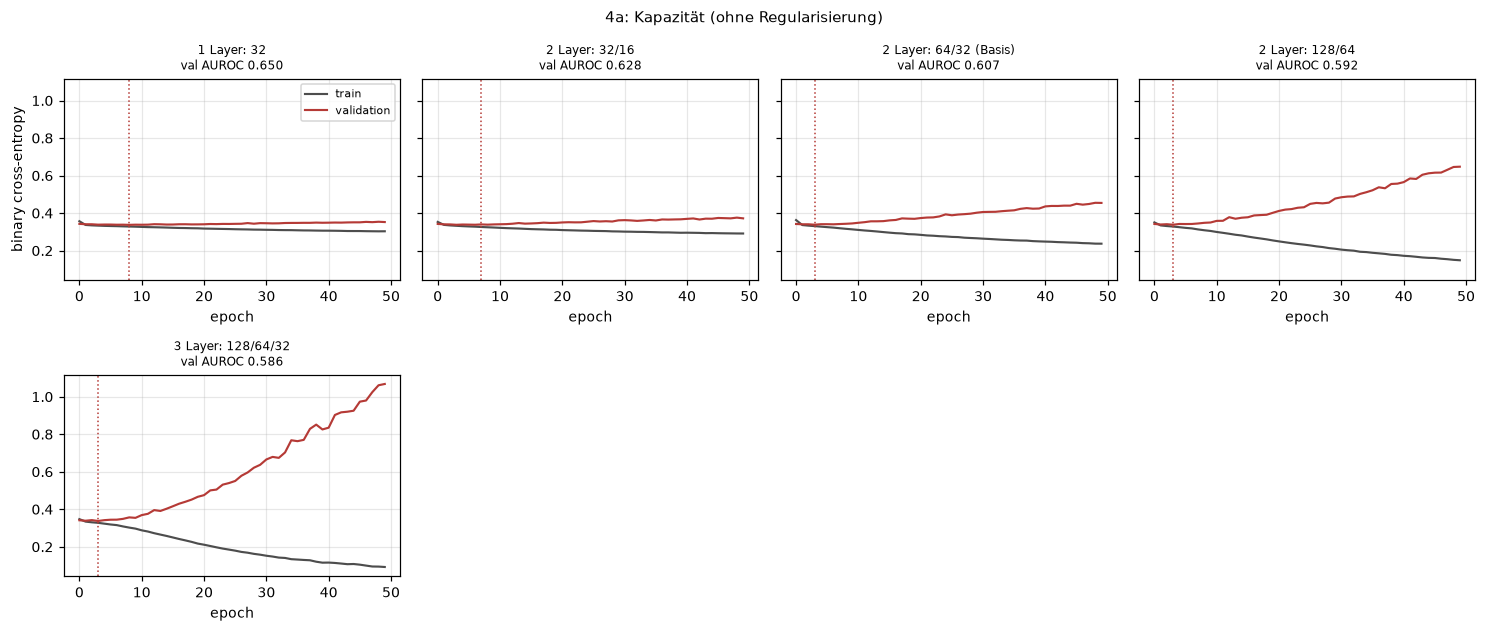

In [14]:
# 4a: Kapazität variieren, OHNE Regularisierung
runs_cap = [
    run_reg("1 Layer: 32",            units=(32,)),
    run_reg("2 Layer: 32/16",         units=(32, 16)),
    run_reg("2 Layer: 64/32 (Basis)", units=(64, 32)),
    run_reg("2 Layer: 128/64",        units=(128, 64)),
    run_reg("3 Layer: 128/64/32",     units=(128, 64, 32)),
]
plot_runs(runs_cap, "4a: Kapazität (ohne Regularisierung)")

**Interpretation 4a:** Bei allen Netzen sinkt der Trainingsverlust die ganze Zeit, der Validierungsverlust aber nur in den ersten paar Epochen (beste Epoche ca. 3, bei 32 und 32/16 ca. 7–8). Danach steigt er wieder an, das Netz overfittet also, so wie in NB2 §7. Je größer das Netz, desto stärker: Beim 32er-Netz bleiben die Kurven fast parallel (val AUROC 0,650), beim 3-Layer-Netz steigt der Validierungsverlust bis über 1,0 (0,586). Ohne Regularisierung ist kein Netz besser als die logistische Regression (0,653). 
Die zwei großen Netze lassen wir deshalb weg und testen in 4b, ob die drei kleineren Netze (32, 32/16, 64/32) mit Regularisierung besser werden.

#### 4b Auf Basis der Kapazität Regularieserer herausfinden

32 + Early Stopping                epochs run  19   val AUROC 0.6656
32 + Dropout 0.3                   epochs run  50   val AUROC 0.6590
32 + L2 1e-3                       epochs run  50   val AUROC 0.6620
32 + Dropout 0.3 + ES              epochs run  32   val AUROC 0.6650
32/16 + Early Stopping             epochs run  18   val AUROC 0.6612
32/16 + Dropout 0.3                epochs run  50   val AUROC 0.6469
32/16 + L2 1e-3                    epochs run  50   val AUROC 0.6576
32/16 + Dropout 0.3 + ES           epochs run  26   val AUROC 0.6655
64/32 + Early Stopping             epochs run  14   val AUROC 0.6559
64/32 + Dropout 0.3                epochs run  50   val AUROC 0.6355
64/32 + L2 1e-3                    epochs run  50   val AUROC 0.6576
64/32 + Dropout 0.3 + ES           epochs run  20   val AUROC 0.6608


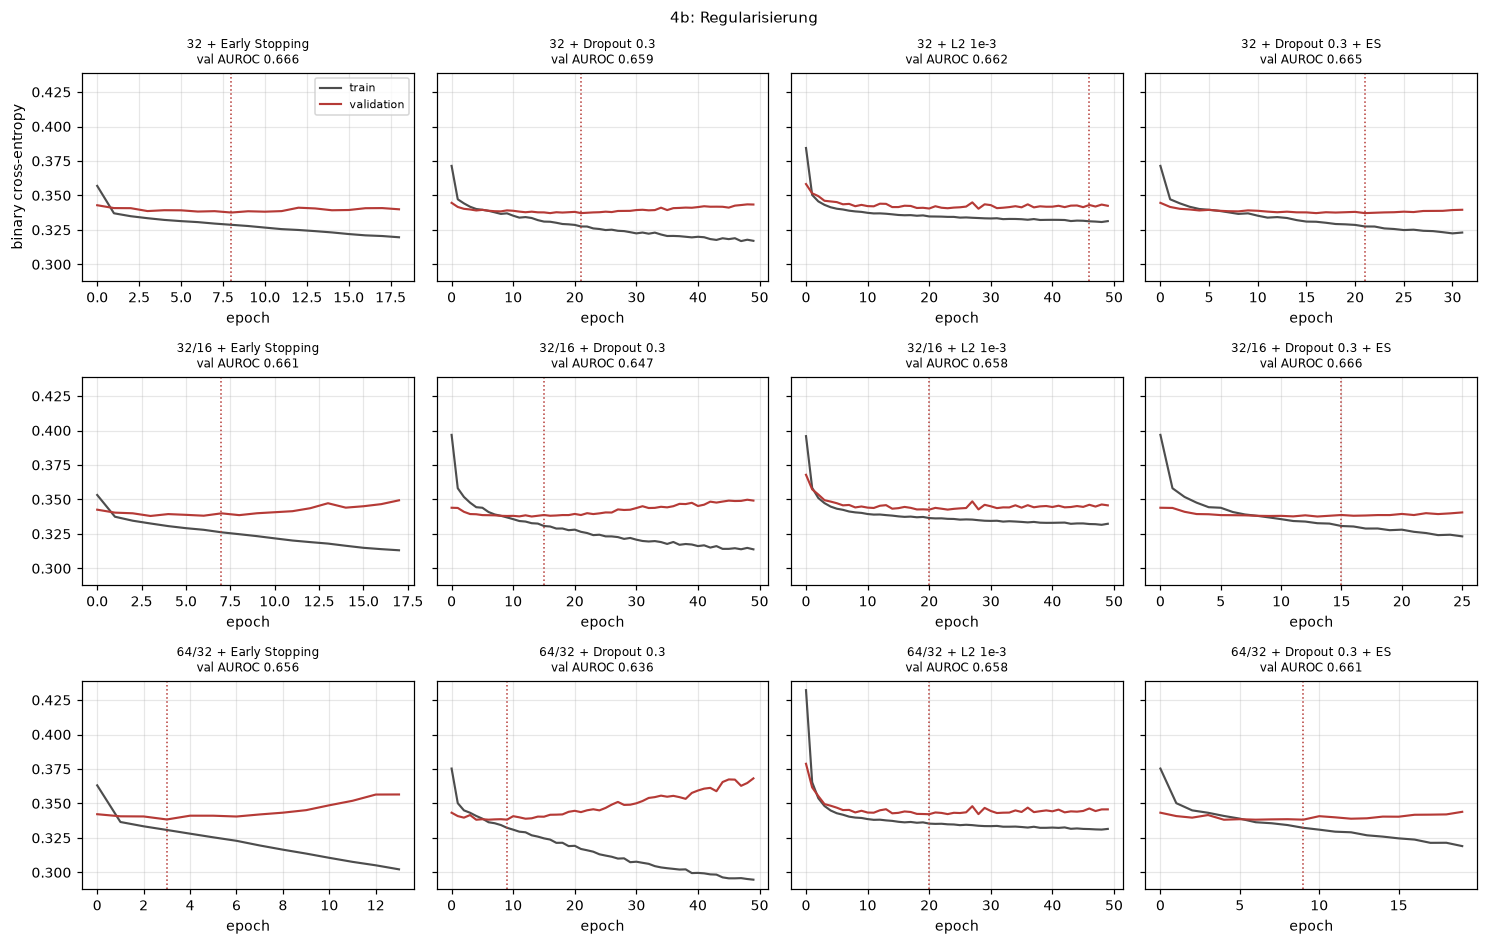

In [15]:
# 4b: Regularisierer auf den drei kleineren Netzen aus 4a testen
CAPS = {"32": (32,), "32/16": (32, 16), "64/32": (64, 32)}

runs_reg = []
for name, units in CAPS.items():
    runs_reg += [
        run_reg(f"{name} + Early Stopping",     units=units, early=True),
        run_reg(f"{name} + Dropout 0.3",        units=units, p_drop=0.3),
        run_reg(f"{name} + L2 1e-3",            units=units, l2=1e-3),
        run_reg(f"{name} + Dropout 0.3 + ES",   units=units, p_drop=0.3, early=True),
    ]

plot_runs(runs_reg, "4b: Regularisierung")

**Interpretation 4b:**
Mit Regularisierung verbessern sich alle drei Netze deutlich gegenüber 4a (z. B. 64/32: von 0,607 auf bis zu 0,661). Die meisten Varianten liegen jetzt bei einer val AUROC von ca. 0,66 und damit über der logistischen Regression (0,653).
- **Early Stopping:** Das Training stoppt nach 14–19 Epochen, bevor das Overfitting beginnt (0,666 / 0,661 / 0,656).
- **Dropout 0.3 (ohne Early Stopping):** Beim 32er-Netz reicht das aus (0,659). Bei 32/16 und 64/32 steigt der Validierungsverlust trotzdem nach ca. 10–15 Epochen wieder an, die AUROC ist schlechter (0,647 bzw. 0,636). Dropout allein reicht bei den größeren Netzen also nicht.
- **L2 1e-3:** Trainings- und Validierungskurve bleiben über alle 50 Epochen nah beieinander, es tritt praktisch kein Overfitting mehr auf (0,662 / 0,658 / 0,658).
- **Dropout 0.3 + Early Stopping:** Gute Ergebnisse bei allen Netzen (0,665 / 0,666 / 0,661).

Die drei besten Varianten (32 + Early Stopping, 32/16 + Dropout + ES, 32 + Dropout + ES) liegen innerhalb von 0,001. Ob solche Unterschiede echt sind, prüfen wir in 4d mit mehreren Seeds. Für 4c verwenden wir das kleinste Netz (32) mit Dropout 0.3 und Early Stopping, da es das einfachste Netz ist und die Kombination beider Regularisierer eine stabile, flache Validierungskurve liefert.

#### 4c Auf Basis BEST (Capacity und Regularizes) optimizer festlegen

Adam (lr 1e-3)                     epochs run  32   val AUROC 0.6650
SGD + Momentum (lr 1e-2)           epochs run  50   val AUROC 0.6552
RMSprop (lr 1e-3)                  epochs run  28   val AUROC 0.6595


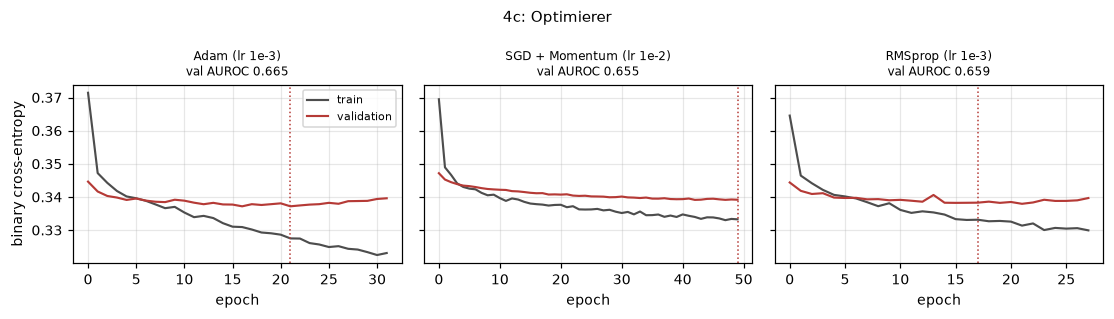

In [16]:
# 4c: Optimierer vergleichen, auf Basis der besten Kapazität + Regularisierung aus 4b
CAP = (32,)                               # beste Kapazität aus 4b
BEST_REG = dict(p_drop=0.3, early=True)   # bester Regularisierer aus 4b

runs_opt = [
    run_reg("Adam (lr 1e-3)",           units=CAP, optimizer="adam",    **BEST_REG),
    run_reg("SGD + Momentum (lr 1e-2)", units=CAP, optimizer="sgd",     **BEST_REG),
    run_reg("RMSprop (lr 1e-3)",        units=CAP, optimizer="rmsprop", **BEST_REG),
]
plot_runs(runs_opt, "4c: Optimierer")

**Interpretation 4c:** Adam (0,665) und RMSprop (0,660) verhalten sich sehr ähnlich: Der Verlust fällt in den ersten Epochen schnell, die beste Epoche liegt bei ca. 21 bzw. 17, danach greift Early Stopping. SGD mit Momentum lernt deutlich langsamer. Die beste Epoche ist erst bei 49, das Netz war nach 50 Epochen also noch nicht fertig (0,655). Mit mehr Epochen wäre SGD wahrscheinlich ähnlich gut. 
Der Optimierer ändert hier also vor allem, wie schnell das Netz lernt. Wir bleiben bei Adam, weil er den besten Wert hatte und auch in NB2 verwendet wird.

#### 4d Bestes Modell 

In [17]:
# 4d: Wie stark schwankt das Ergebnis nur durch den Zufall (Gewichtsinitialisierung, Dropout, Batch-Reihenfolge)?
BEST = dict(units=CAP, optimizer="adam", **BEST_REG)   # finale Konfiguration: 32, Dropout 0.3, ES, Adam

seed_aucs = [run_reg(f"BEST, seed {s}", seed=s, **BEST)[3] for s in [0, 1, 2, 3, 4]]
print(f"\nBEST über 5 Seeds: val AUROC = {np.mean(seed_aucs):.4f} ± {np.std(seed_aucs):.4f}")
print(f"Logistische Regression:        val AUROC = {auc_lr_val:.4f}")

# Übersichtstabelle aller Konfigurationen
display(pd.DataFrame(results).sort_values("val AUROC", ascending=False).reset_index(drop=True))

BEST, seed 0                       epochs run  27   val AUROC 0.6658
BEST, seed 1                       epochs run  26   val AUROC 0.6621
BEST, seed 2                       epochs run  30   val AUROC 0.6642
BEST, seed 3                       epochs run  23   val AUROC 0.6655
BEST, seed 4                       epochs run  28   val AUROC 0.6643

BEST über 5 Seeds: val AUROC = 0.6644 ± 0.0013
Logistische Regression:        val AUROC = 0.6532


,Konfiguration,Epochen,val AUROC
0,"BEST, seed 0",27,0.6658
1,32 + Early Stopping,19,0.6656
2,32/16 + Dropout 0.3 + ES,26,0.6655
3,"BEST, seed 3",23,0.6655
4,32 + Dropout 0.3 + ES,32,0.6650
5,Adam (lr 1e-3),32,0.6650
6,"BEST, seed 4",28,0.6643
7,"BEST, seed 2",30,0.6642
8,"BEST, seed 1",26,0.6621
9,32 + L2 1e-3,50,0.6620


**Interpretation 4d:**
Wir haben das beste Modell (32 Neuronen, Dropout 0.3, Early Stopping, Adam) mit 5 verschiedenen Seeds trainiert. Die val AUROC liegt zwischen 0,662 und 0,666 (Mittelwert 0,664 ± 0,001). Das ist die Schwankung, die nur durch den Zufall entsteht (Startgewichte, Dropout, Reihenfolge der Batches).

Damit können wir unsere bisherigen Ergebnisse einordnen:
- **Echt** ist der Unterschied zwischen den Netzen ohne Regularisierung (4a, 0,59–0,65) und mit Regularisierung (ca. 0,66). Dieser ist viel größer als die Seed-Schwankung.
- **Echt** ist auch, dass das Netz auf dem Validierungsset bei allen Seeds über der logistischen Regression (0,653) liegt. Der Abstand ist mit ca. 0,01 aber klein.
- **Nicht messbar** sind die Unterschiede zwischen den besten regularisierten Varianten aus 4b (unter 0,001). Wir können also nicht sagen, welcher Regularisierer der beste ist. Klar schlechter ist nur Dropout ohne Early Stopping bei den größeren Netzen.

**Finales Modell:** 1 Hidden Layer mit 32 Neuronen, Dropout 0.3, Early Stopping, Adam. Ob das Netz auch auf dem Testset besser ist, prüfen wir in Aufgabe 5.

### 5 Comparison and Limitations [1P]
Jetzt verwenden wir das Testset genau einmal und werten beide Modelle auf demselben (patientenweise gruppierten) Testset aus.
Für die Konfusionsmatrix brauchen wir eine Schwelle. Da nur ca. 11 % der Aufenthalte positiv sind, würde die Schwelle 0,5 fast niemanden als positiv vorhersagen. Wir verwenden deshalb für beide Modelle den Anteil der Positiven im Trainingsset (ca. 0,11) als Schwelle. Die Schwelle ist nicht optimiert, aber beide Modelle werden gleich behandelt.

FINAL Netz                         epochs run  32   val AUROC 0.6650
Test AUROC  logistische Regression: 0.6681
Test AUROC  neuronales Netz:        0.6702
Differenz (NN - LR):                +0.0021

Schwelle = 0.114

Logistische Regression


,vorhergesagt: 0,vorhergesagt: 1
echt: keine frühe WA,14282,6655
echt: frühe WA,1182,1481


Sensitivität 0.556   Spezifität 0.682   PPV 0.182

Neuronales Netz


,vorhergesagt: 0,vorhergesagt: 1
echt: keine frühe WA,13310,7627
echt: frühe WA,1040,1623


Sensitivität 0.609   Spezifität 0.636   PPV 0.175


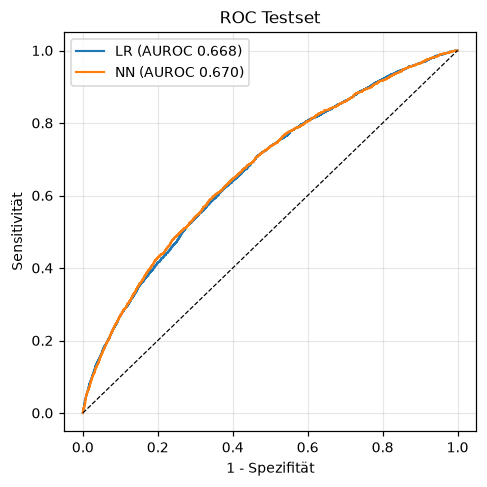


Differenz NN - LR: +0.0021   95%-Bootstrap-Intervall [-0.0021, +0.0062]


In [18]:
from sklearn.metrics import roc_curve

# finales Netz mit dem Standard-SEED trainieren (reproduzierbar)
_, nn_final, h_final, _ = run_reg("FINAL Netz", **BEST)

# EINMALIGE Auswertung auf dem Testset
p_te_nn = probs(nn_final, X_test)
p_te_lr = lr_model.predict_proba(X_test)[:, 1]

auc_nn_test = roc_auc_score(Y_test, p_te_nn)
auc_lr_test = roc_auc_score(Y_test, p_te_lr)
print(f"Test AUROC  logistische Regression: {auc_lr_test:.4f}")
print(f"Test AUROC  neuronales Netz:        {auc_nn_test:.4f}")
print(f"Differenz (NN - LR):                {auc_nn_test - auc_lr_test:+.4f}")

# Konfusionsmatrix bei gleicher Schwelle für beide Modelle
thr = Y_train.mean()
print(f"\nSchwelle = {thr:.3f}")
for name, p in [("Logistische Regression", p_te_lr), ("Neuronales Netz", p_te_nn)]:
    tn, fp, fn, tp = confusion_matrix(Y_test, (p >= thr).astype(int)).ravel()
    print(f"\n{name}")
    display(pd.DataFrame([[tn, fp], [fn, tp]],
                         index=["echt: keine frühe WA", "echt: frühe WA"],
                         columns=["vorhergesagt: 0", "vorhergesagt: 1"]))
    print(f"Sensitivität {tp/(tp+fn):.3f}   Spezifität {tn/(tn+fp):.3f}   PPV {tp/(tp+fp):.3f}")

# ROC-Kurven beider Modelle
plt.figure(figsize=(4.5, 4.5))
for name, p, auc in [("LR", p_te_lr, auc_lr_test), ("NN", p_te_nn, auc_nn_test)]:
    fpr, tpr, _ = roc_curve(Y_test, p)
    plt.plot(fpr, tpr, lw=1.4, label=f"{name} (AUROC {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("1 - Spezifität"); plt.ylabel("Sensitivität")
plt.title("ROC Testset"); plt.legend()
plt.tight_layout(); plt.show()

# Ist der Unterschied echt? Einfaches Bootstrap auf dem Testset (1000 Ziehungen mit Zurücklegen)
rng = np.random.default_rng(SEED)
n = len(Y_test)
diffs = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    diffs.append(roc_auc_score(Y_test[idx], p_te_nn[idx]) - roc_auc_score(Y_test[idx], p_te_lr[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nDifferenz NN - LR: {auc_nn_test - auc_lr_test:+.4f}   95%-Bootstrap-Intervall [{lo:+.4f}, {hi:+.4f}]")

**Ergebnis:** Auf dem Testset erreicht die logistische Regression eine AUROC von 0,668, das neuronale Netz 0,670. Die Differenz beträgt nur 0,002, das 95%-Bootstrap-Intervall der Differenz reicht von −0,002 bis +0,006 und enthält damit die 0. Auch die ROC-Kurven liegen fast genau übereinander.

Bei der Schwelle 0,114 erkennt die logistische Regression 56 % der frühen Wiederaufnahmen (Spezifität 0,68), das Netz 61 % (Spezifität 0,64). Nur ca. 18 % der als positiv vorhergesagten Aufenthalte werden tatsächlich innerhalb von 30 Tagen wieder aufgenommen (PPV). Es gibt also sehr viele Fehlalarme (6.655 bzw. 7.627), was am Klassenungleichgewicht liegt. Das Netz sagt bei derselben Schwelle mehr Fälle positiv vorher, deshalb ist seine Sensitivität höher und seine Spezifität niedriger. Besser ist es dadurch aber nicht, es liegt nur an einer anderen Stelle derselben ROC-Kurve.

**Schlägt das Netz die logistische Regression?** Nein, nicht in einem Ausmaß, das etwas bedeutet. Auf dem Validierungsset lag das Netz noch ca. 0,011 vorne, auf dem Testset nur noch 0,002. Der Validierungswert war etwas zu optimistisch, weil wir dort aus vielen Konfigurationen die beste ausgewählt haben. Bei praktisch gleicher Leistung wäre die logistische Regression vorzuziehen, weil sie einfacher und besser interpretierbar ist.

**Was diese Zahlen NICHT zeigen:**
- Ob die vorhergesagten Wahrscheinlichkeiten stimmen (Kalibrierung): Die AUROC misst nur die Rangfolge.
- Welche Schwelle klinisch sinnvoll ist: Unsere Schwelle ist nicht begründet, sondern nur für beide Modelle gleich gewählt.
- Ob das Modell Patient:innen hilft, also ob dadurch tatsächlich Wiederaufnahmen verhindert werden.
- Ob das Modell auf andere Krankenhäuser, andere Länder oder heutige Daten übertragbar ist: Die Daten stammen aus US-Krankenhäusern von 1999–2008, es gab keine externe Validierung.
- Ursachen: Die Merkmale zeigen Zusammenhänge, keine Kausalität.
- Ob das Modell für alle Untergruppen (z. B. Alter, Geschlecht) gleich gut funktioniert.
- Wiederaufnahmen in anderen Krankenhäusern sind vermutlich nicht erfasst.
- Alle Zahlen beruhen auf einem einzigen Split.

### 6 Random versus Grouped Split [1P* Bonus]
Wir trainieren das finale Modell ein zweites Mal, diesmal mit einem zufälligen Split über die Aufenthalte (gleiche Anteile 60/15/25 %, stratifiziert), ohne Rücksicht auf patient_nbr. Das Preprocessing wird wieder nur auf dem neuen Trainingsset gefittet. Danach vergleichen wir die Test-AUROC mit dem gruppierten Split aus Aufgabe 5.

In [19]:
from sklearn.base import clone

# Random Split über Zeilen (Aufenthalte), gleiche Anteile wie beim gruppierten Split
idx_all = np.arange(len(X_df))
tr_r, tmp_r = train_test_split(idx_all, train_size=0.6, random_state=SEED, stratify=y)
va_r, te_r  = train_test_split(tmp_r, train_size=0.375, random_state=SEED, stratify=y[tmp_r])

# Wie viele Test-Aufenthalte gehören zu Patienten, die auch im Training vorkommen?
overlap = groups.iloc[te_r].isin(set(groups.iloc[tr_r])).mean()
print(f"Random Split: {100*overlap:.1f}% der Test-Aufenthalte stammen von Patienten aus dem Training")

# Preprocessing neu fitten (nur auf dem neuen Trainingsset!)
prep_r = clone(prep)
Xtr_r = prep_r.fit_transform(X_df.iloc[tr_r]).astype("float32")
Xva_r = prep_r.transform(X_df.iloc[va_r]).astype("float32")
Xte_r = prep_r.transform(X_df.iloc[te_r]).astype("float32")

# gleiches Modell (BEST) auf dem Random Split trainieren
data_r = (Xtr_r, y[tr_r].astype("float32"), Xva_r, y[va_r].astype("float32"), y[va_r])
_, nn_r, h_r, _ = run_reg("BEST, Random Split", data=data_r, **BEST)

auc_test_random = roc_auc_score(y[te_r], probs(nn_r, Xte_r))

print(f"\nTest AUROC  gruppierter Split: {auc_nn_test:.4f}")
print(f"Test AUROC  Random Split:      {auc_test_random:.4f}")
print(f"Differenz (Random - Gruppiert): {auc_test_random - auc_nn_test:+.4f}")
print(f"(zum Vergleich Seed-Schwankung aus 4d: ± {np.std(seed_aucs):.4f})")

Random Split: 35.2% der Test-Aufenthalte stammen von Patienten aus dem Training
BEST, Random Split                 epochs run  26   val AUROC 0.6771

Test AUROC  gruppierter Split: 0.6702
Test AUROC  Random Split:      0.6707
Differenz (Random - Gruppiert): +0.0005
(zum Vergleich Seed-Schwankung aus 4d: ± 0.0013)


**Ergebnis:** Beim Random Split stammen 35,2 % der Test-Aufenthalte von Patient:innen, die mit einem anderen Aufenthalt auch im Trainingsset vorkommen. Die Test-AUROC beträgt beim Random Split 0,671, beim gruppierten Split 0,670. Die Differenz von +0,0005 ist kleiner als die Seed-Schwankung aus 4d (± 0,001), es gibt also keinen messbaren Unterschied.

**Richtung:** Erwartet wird, dass der Random Split besser abschneidet. Wenn dieselbe Person im Training und im Test vorkommt, kann das Modell sie an ähnlichen Merkmalen wiedererkennen (Data Leakage), und die Leistung wird zu optimistisch geschätzt. Die Richtung stimmt hier zwar, der Unterschied ist aber zu klein, um etwas zu bedeuten. Deutlicher zeigt sie sich auf dem Validierungsset (0,677 beim Random Split vs. 0,665 beim gruppierten Split).

**Mögliche Gründe, warum der Effekt hier so klein ist:**
- Ca. 65 % der Test-Aufenthalte stammen trotzdem von neuen Patient:innen, da die meisten Patient:innen nur einen Aufenthalt haben (siehe 2b).
- Unser finales Modell ist sehr klein (32 Neuronen) und regularisiert (Dropout, Early Stopping). Es kann einzelne Patient:innen kaum auswendig lernen. Ein großes Netz ohne Regularisierung würde vermutlich stärker vom Leakage profitieren.
- Ein Teil der Vorgeschichte steckt bereits erlaubt in den Features (z. B. number_inpatient).
- Beide Splits haben unterschiedliche Testsets. Ein Teil des Unterschieds ist daher Zufall durch die Aufteilung. Für eine sichere Aussage müsste man beide Varianten mit mehreren Split-Seeds wiederholen.

**Fazit:** Bei diesem Modell und Datensatz ist der Leakage-Effekt nicht messbar. Trotzdem ist der gruppierte Split die richtige Wahl, weil nur er die echte Situation abbildet: Das Modell soll im Einsatz neue Patient:innen beurteilen.